# Task 4 — Honest Evaluation and Risk Bands

Evaluate the balanced Logistic Regression baseline using out-of-fold predictions from stratified 5-fold cross-validation. Compare with the supplied benchmark, inspect calibration, apply the company's risk-band rule, and write a manager-readable note.

**Target:** `left_within_12m`  
**Responsible use:** Scores support human review only and must never be the sole basis for employment decisions. No unlock/answer-key files are used.

In [1]:
from pathlib import Path
import sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.calibration import calibration_curve

warnings.filterwarnings("ignore", category=FutureWarning)
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
DATA_DIR, EVIDENCE_DIR, REPORTS_DIR = ROOT/"data", ROOT/"evidence", ROOT/"reports"
EVIDENCE_DIR.mkdir(exist_ok=True)
REPORTS_DIR.mkdir(exist_ok=True)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.features.build_features import build_features
from cortexhr_helpers import binary_report, risk_bands

ATTRITION_PATH = DATA_DIR/"attrition_dataset.csv"
ATTENDANCE_PATH = DATA_DIR/"attendance_monthly_features.csv"
PAYROLL_PATH = DATA_DIR/"payroll_monthly_features.csv"
BENCHMARK_PATH = DATA_DIR/"baseline_benchmarks.csv"
for p in [ATTRITION_PATH, ATTENDANCE_PATH, PAYROLL_PATH, BENCHMARK_PATH]:
    if not p.exists():
        raise FileNotFoundError(f"Missing required file: {p}")
print("Project root:", ROOT, "| Input files verified.")

Project root: /workspace | Input files verified.


## 1. Load the data and rebuild Task 2 features

In [2]:
employees = pd.read_csv(ATTRITION_PATH)
attendance = pd.read_csv(ATTENDANCE_PATH)
payroll = pd.read_csv(PAYROLL_PATH)
benchmarks = pd.read_csv(BENCHMARK_PATH)
df = build_features(employees, attendance, payroll)

TARGET = "left_within_12m"
if TARGET not in df.columns:
    raise ValueError(f"Target column {TARGET!r} not found.")
df = df.loc[df[TARGET].notna()].copy()
y = pd.to_numeric(df[TARGET], errors="raise").astype(int)
print(f"Labelled rows: {len(df):,}")
print(f"Actual leavers: {int(y.sum()):,} ({y.mean():.2%})")
print(f"Stayed: {int((y == 0).sum()):,} ({(y == 0).mean():.2%})")
display(y.value_counts().rename(index={0:"Stayed (0)",1:"Left (1)"}).to_frame("Rows"))

Labelled rows: 2,389
Actual leavers: 349 (14.61%)
Stayed: 2,040 (85.39%)


,Rows
left_within_12m,
Stayed (0),2040
Left (1),349


## 2. Prepare safe predictors and preprocessing\n\nPreprocessing is kept inside the pipeline, so each cross-validation fold fits its own imputers, scaler, and encoder.

In [3]:
FORBIDDEN_COLUMNS = {
    "row_id", "employee_id", "observation_date", TARGET,
    "voluntary_left_within_12m", "source", "exit_date",
    "resignation_date", "exit_reason", "exit_interview_done",
    "fnf_settlement_amount",
}
X = df.drop(columns=[c for c in FORBIDDEN_COLUMNS if c in df.columns]).copy()
X = X.drop(columns=[c for c in X.columns if X[c].isna().all()])
date_cols = [c for c in X.columns if pd.api.types.is_datetime64_any_dtype(X[c])]
X = X.drop(columns=date_cols)

numeric_columns = X.select_dtypes(include=["number","bool"]).columns.tolist()
categorical_columns = [c for c in X.columns if c not in numeric_columns]
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_columns),
    ("categorical", categorical_pipeline, categorical_columns),
], remainder="drop")
model = Pipeline([
    ("preprocess", clone(preprocessor)),
    ("model", LogisticRegression(class_weight="balanced", max_iter=3000, random_state=42)),
])
print("Predictor columns:", X.shape[1])
print("Numeric:", len(numeric_columns), "| Categorical:", len(categorical_columns))
print("Forbidden columns remaining:", sorted(FORBIDDEN_COLUMNS.intersection(X.columns)))
assert not FORBIDDEN_COLUMNS.intersection(X.columns)
assert len(X) == len(y)

Predictor columns: 45
Numeric: 39 | Categorical: 6
Forbidden columns remaining: []


## 3. Generate honest out-of-fold predictions\n\nThis reproduces Task 3's stratified five-fold configuration. Each row's score is generated by a model that did not train on that row.

In [4]:
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof_probabilities = cross_val_predict(
    model, X, y, cv=CV, method="predict_proba", n_jobs=None
)[:, 1]
y_true = y.to_numpy()
y_score = np.asarray(oof_probabilities)
assert len(y_true) == len(y_score)
assert np.isfinite(y_score).all() and ((y_score >= 0) & (y_score <= 1)).all()
print("Out-of-fold predictions:", len(y_score))
print(f"Mean score: {y_score.mean():.3f} | Observed leaver rate: {y_true.mean():.3f}")

Out-of-fold predictions: 2389
Mean score: 0.400 | Observed leaver rate: 0.146


## 4. Metrics table using `binary_report()`

,Metric,Value
0,ROC-AUC,0.699
1,PR-AUC / Average Precision,0.297
2,Precision at top 10%,0.349
3,Recall at top 10%,0.238
4,F1 at top 10%,0.283
5,Observed leaver base rate,0.146


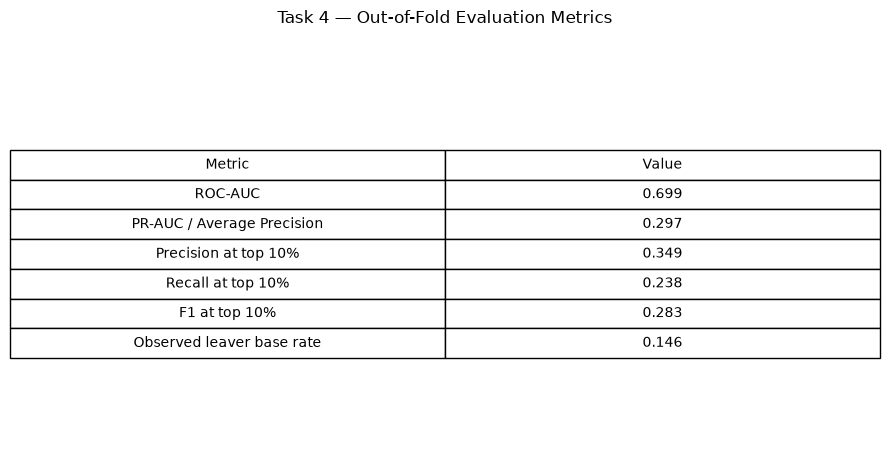

In [5]:
report = binary_report(y_true, y_score, top_fraction=0.10)
metrics_table = pd.DataFrame([
    {"Metric":"ROC-AUC", "Value":report["roc_auc"]},
    {"Metric":"PR-AUC / Average Precision", "Value":report["pr_auc"]},
    {"Metric":"Precision at top 10%", "Value":report["precision_at_top"]},
    {"Metric":"Recall at top 10%", "Value":report["recall_at_top"]},
    {"Metric":"F1 at top 10%", "Value":report["f1_at_top"]},
    {"Metric":"Observed leaver base rate", "Value":report["base_rate"]},
])
display(metrics_table.round(3))
metrics_table.to_csv(REPORTS_DIR/"task4_metrics.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 4.8))
ax.axis("off")
tbl = ax.table(cellText=metrics_table.round(3).values,
               colLabels=metrics_table.columns, cellLoc="center", loc="center")
tbl.auto_set_font_size(False); tbl.set_fontsize(10); tbl.scale(1, 1.6)
ax.set_title("Task 4 — Out-of-Fold Evaluation Metrics", pad=18)
fig.tight_layout()
fig.savefig(EVIDENCE_DIR/"task4_metrics_table.png", dpi=180, bbox_inches="tight")
plt.show()

## 5. Compare with the supplied benchmark

In [6]:
display(benchmarks)
benchmark_mask = benchmarks["model"].astype(str).str.contains(
    r"Logistic Regression.*balanced|balanced.*Logistic Regression",
    case=False, regex=True
)
benchmark_rows = benchmarks.loc[benchmark_mask]
benchmark_comparison = None
benchmark_auc_text = "not available"
if benchmark_rows.empty:
    print("No balanced Logistic Regression benchmark matched automatically. Review model names above.")
else:
    benchmark_row = benchmark_rows.iloc[0]
    benchmark_auc_text = f'{float(benchmark_row["roc_auc_mean"]):.3f}'
    benchmark_comparison = pd.DataFrame([
        {"Metric":"ROC-AUC", "Measured":report["roc_auc"],
         "Benchmark":float(benchmark_row["roc_auc_mean"]),
         "Difference":report["roc_auc"]-float(benchmark_row["roc_auc_mean"])},
        {"Metric":"PR-AUC", "Measured":report["pr_auc"],
         "Benchmark":float(benchmark_row["pr_auc_mean"]),
         "Difference":report["pr_auc"]-float(benchmark_row["pr_auc_mean"])},
    ])
    display(benchmark_comparison.round(3))
    benchmark_comparison.to_csv(REPORTS_DIR/"task4_benchmark_comparison.csv", index=False)

,model,roc_auc_mean,roc_auc_sd,pr_auc_mean,precision_mean,recall_mean,f1_mean,accuracy_mean,comment
0,Dummy (always stays),0.500,0.000,0.146,0.000,0.000,0.000,0.854,Looks 85% accurate yet catches nobody: why acc...
1,Logistic Regression (class_weight=balanced),0.713,0.010,0.332,0.260,0.630,0.368,0.683,Clean features only (reference target)
2,"Decision Tree (depth 4, balanced)",0.650,0.019,0.256,0.234,0.524,0.322,0.676,Clean features only (reference target)
3,"Random Forest (300 trees, balanced)",0.715,0.018,0.336,0.523,0.089,0.151,0.854,Clean features only (reference target)
4,LEAKY Logistic Regression (adds exit information),1.000,0.000,1.000,1.000,1.000,1.000,1.000,Too good to be true: this is data leakage


,Metric,Measured,Benchmark,Difference
0,ROC-AUC,0.699,0.713,-0.014
1,PR-AUC,0.297,0.332,-0.035


## 6. Calibration curve\n\nThe diagonal represents ideal calibration. Points above it mean the observed leaver rate is higher than the mean predicted score in that bin; points below it mean the reverse.

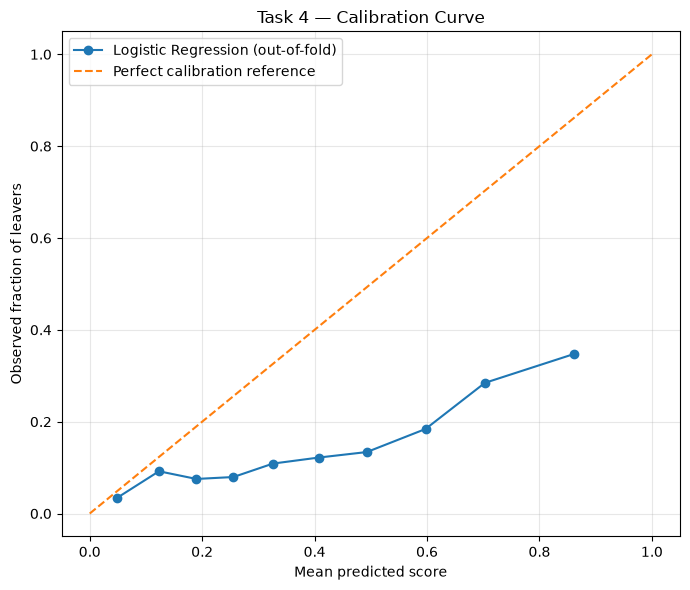

,Mean predicted score,Observed leaver fraction
0,0.048,0.033
1,0.123,0.092
2,0.190,0.075
3,0.256,0.079
4,0.326,0.109
5,0.407,0.122
6,0.493,0.134
7,0.597,0.184
8,0.703,0.285
9,0.861,0.347


Some bins differ noticeably from the diagonal. Treat scores primarily as ranking signals, not verified individual probabilities.


In [7]:
fraction_positive, mean_predicted = calibration_curve(
    y_true, y_score, n_bins=10, strategy="quantile"
)
fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(mean_predicted, fraction_positive, marker="o", label="Logistic Regression (out-of-fold)")
ax.plot([0,1], [0,1], linestyle="--", label="Perfect calibration reference")
ax.set_xlabel("Mean predicted score"); ax.set_ylabel("Observed fraction of leavers")
ax.set_title("Task 4 — Calibration Curve"); ax.legend(); ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(EVIDENCE_DIR/"task4_calibration_curve.png", dpi=180, bbox_inches="tight")
plt.show()
calibration_table = pd.DataFrame({
    "Mean predicted score":mean_predicted,
    "Observed leaver fraction":fraction_positive,
})
display(calibration_table.round(3))
calibration_table.to_csv(REPORTS_DIR/"task4_calibration_values.csv", index=False)
diffs = fraction_positive - mean_predicted
if np.all(np.abs(diffs) < 0.05):
    print("Observed fractions are relatively close to predicted scores in these bins; this does not guarantee future calibration.")
else:
    print("Some bins differ noticeably from the diagonal. Treat scores primarily as ranking signals, not verified individual probabilities.")

## 7. Risk-band counts using `risk_bands()`\n\nThe helper defines High as the top 10%, Medium as the next 20%, and Low as the rest. Ties at quantile boundaries can affect actual band sizes.

In [8]:
bands = risk_bands(y_score)
risk_results = pd.DataFrame({
    "actual_left":y_true, "predicted_score":y_score, "risk_band":bands
})
band_order = ["High", "Medium", "Low"]
risk_summary = risk_results.groupby("risk_band").agg(
    employees=("actual_left","size"),
    observed_leavers=("actual_left","sum"),
    mean_predicted_score=("predicted_score","mean"),
).reindex(band_order)
risk_summary["employee_percent"] = risk_summary["employees"]/len(risk_results)*100
risk_summary["leaver_percent_of_all_leavers"] = risk_summary["observed_leavers"]/max(1,int(y_true.sum()))*100
risk_summary["observed_leaver_rate"] = risk_summary["observed_leavers"]/risk_summary["employees"]
display(risk_summary.round(3))
risk_summary.to_csv(REPORTS_DIR/"task4_risk_band_counts.csv")
print(risk_results["risk_band"].value_counts())

,employees,observed_leavers,mean_predicted_score,employee_percent,leaver_percent_of_all_leavers,observed_leaver_rate
risk_band,,,,,,
High,239,83,0.861,10.004,23.782,0.347
Medium,478,112,0.650,20.008,32.092,0.234
Low,1672,154,0.263,69.987,44.126,0.092


risk_band
Low       1672
Medium     478
High       239
Name: count, dtype: int64


## 8. High-band leaver capture and top-10% lift

In [9]:
high_mask = risk_results["risk_band"].eq("High")
high_count = int(high_mask.sum())
high_leavers = int(risk_results.loc[high_mask, "actual_left"].sum())
total_leavers = int(y_true.sum())
high_precision = high_leavers/high_count if high_count else 0.0
high_capture = high_leavers/total_leavers if total_leavers else 0.0
base_rate = float(y_true.mean())
top10_precision = float(report["precision_at_top"])
top10_recall = float(report["recall_at_top"])
top10_lift = top10_precision/base_rate if base_rate > 0 else np.nan

high_band_metrics = pd.DataFrame([
    {"Measure":"Employees in High band","Value":high_count},
    {"Measure":"Actual leavers in High band","Value":high_leavers},
    {"Measure":"Leaver rate within High band","Value":high_precision},
    {"Measure":"Fraction of all leavers in High band","Value":high_capture},
    {"Measure":"Top-10% precision","Value":top10_precision},
    {"Measure":"Top-10% recall","Value":top10_recall},
    {"Measure":"Top-10% lift over base rate","Value":top10_lift},
])
display(high_band_metrics.round(3))
high_band_metrics.to_csv(REPORTS_DIR/"task4_high_band_capture.csv", index=False)
print(f"High band contains {high_leavers} of {total_leavers} actual leavers ({high_capture:.1%}).")
print(f"Top-10% lift: {top10_lift:.2f}x the overall leaver base rate.")

,Measure,Value
0,Employees in High band,239.000
1,Actual leavers in High band,83.000
2,Leaver rate within High band,0.347
3,Fraction of all leavers in High band,0.238
4,Top-10% precision,0.349
5,Top-10% recall,0.238
6,Top-10% lift over base rate,2.387


High band contains 83 of 349 actual leavers (23.8%).
Top-10% lift: 2.39x the overall leaver base rate.


## 9. Optional cumulative capture / lift chart

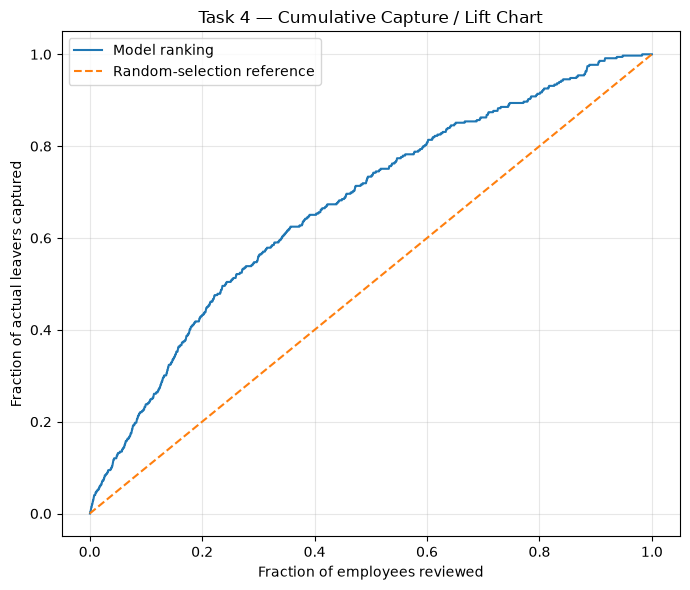

In [10]:
ranked = pd.DataFrame({"actual_left":y_true, "score":y_score}).sort_values(
    "score", ascending=False
).reset_index(drop=True)
ranked["fraction_reviewed"] = np.arange(1,len(ranked)+1)/len(ranked)
ranked["fraction_leavers_captured"] = ranked["actual_left"].cumsum()/max(1,int(y_true.sum()))
fig, ax = plt.subplots(figsize=(7,6))
ax.plot(ranked["fraction_reviewed"], ranked["fraction_leavers_captured"], label="Model ranking")
ax.plot([0,1], [0,1], linestyle="--", label="Random-selection reference")
ax.set_xlabel("Fraction of employees reviewed")
ax.set_ylabel("Fraction of actual leavers captured")
ax.set_title("Task 4 — Cumulative Capture / Lift Chart")
ax.legend(); ax.grid(True, alpha=0.3); fig.tight_layout()
fig.savefig(EVIDENCE_DIR/"task4_lift_chart.png", dpi=180, bbox_inches="tight")
plt.show()

## 10. One-page manager evaluation note

In [14]:
manager_note = f'''# Task 4 — Manager Evaluation Note

## Purpose
The model ranks historical employee records by their score for `left_within_12m`. It can help HR prioritize supportive human review, but it must not make employment decisions.

## Results
- **ROC-AUC:** 0.699; benchmark: 0.713.
- **PR-AUC:** 0.297; benchmark: 0.332.
- **Observed leaver rate:** 14.61%.
- **High band:** 239 employees, including 83 historical leavers.
- **High-band leaver rate:** 34.73%.
- **Historical leavers captured in High band:** 23.78%.
- **Top-10% lift:** 2.39× the overall leaver base rate.

## Risk bands
High is the top-scoring group, Medium is the next 20%, and Low is the remainder, according to the supplied quantile-based rule. These are relative rankings, not validated business thresholds.

## Limitations and responsible use
Predictions are out-of-fold, but historical patterns may not generalize to future employees. Calibration, data quality, and potential historical bias remain concerns; scores should not be interpreted as verified individual probabilities without adequate calibration.

HR should use scores only as one signal for supportive check-ins, verify the employee's current context, and consider other relevant evidence. Never use scores alone for hiring, promotion, compensation, performance ratings, discipline, or termination. Continue monitoring performance, calibration, and fairness.
'''
manager_path = REPORTS_DIR/"task4_manager_evaluation.md"
manager_path.write_text(manager_note, encoding="utf-8")
display(Markdown(manager_note))
print("Saved:", manager_path)

# Task 4 — Manager Evaluation Note

## Purpose
The model ranks historical employee records by their score for `left_within_12m`. It can help HR prioritize supportive human review, but it must not make employment decisions.

## Results
- **ROC-AUC:** 0.699; benchmark: 0.713.
- **PR-AUC:** 0.297; benchmark: 0.332.
- **Observed leaver rate:** 14.61%.
- **High band:** 239 employees, including 83 historical leavers.
- **High-band leaver rate:** 34.73%.
- **Historical leavers captured in High band:** 23.78%.
- **Top-10% lift:** 2.39× the overall leaver base rate.

## Risk bands
High is the top-scoring group, Medium is the next 20%, and Low is the remainder, according to the supplied quantile-based rule. These are relative rankings, not validated business thresholds.

## Limitations and responsible use
Predictions are out-of-fold, but historical patterns may not generalize to future employees. Calibration, data quality, and potential historical bias remain concerns; scores should not be interpreted as verified individual probabilities without adequate calibration.

HR should use scores only as one signal for supportive check-ins, verify the employee's current context, and consider other relevant evidence. Never use scores alone for hiring, promotion, compensation, performance ratings, discipline, or termination. Continue monitoring performance, calibration, and fairness.


Saved: /workspace/reports/task4_manager_evaluation.md


## 11. Final output checks

In [12]:
expected_outputs = [
    REPORTS_DIR/"task4_metrics.csv",
    REPORTS_DIR/"task4_calibration_values.csv",
    REPORTS_DIR/"task4_risk_band_counts.csv",
    REPORTS_DIR/"task4_high_band_capture.csv",
    REPORTS_DIR/"task4_manager_evaluation.md",
    EVIDENCE_DIR/"task4_metrics_table.png",
    EVIDENCE_DIR/"task4_calibration_curve.png",
    EVIDENCE_DIR/"task4_lift_chart.png",
]
if benchmark_comparison is not None:
    expected_outputs.append(REPORTS_DIR/"task4_benchmark_comparison.csv")
output_check = pd.DataFrame({
    "File":[str(p.relative_to(ROOT)) for p in expected_outputs],
    "Exists":[p.exists() for p in expected_outputs],
})
display(output_check)
assert output_check["Exists"].all(), "One or more Task 4 outputs are missing."
print("Task 4 outputs generated. Review metrics and note before submission.")
print("No unlock/answer-key files were opened.")

,File,Exists
0,reports/task4_metrics.csv,True
1,reports/task4_calibration_values.csv,True
2,reports/task4_risk_band_counts.csv,True
3,reports/task4_high_band_capture.csv,True
4,reports/task4_manager_evaluation.md,True
5,evidence/task4_metrics_table.png,True
6,evidence/task4_calibration_curve.png,True
7,evidence/task4_lift_chart.png,True
8,reports/task4_benchmark_comparison.csv,True


Task 4 outputs generated. Review metrics and note before submission.
No unlock/answer-key files were opened.
